
 ## Languages of love: Comparing romantic novels

Sophie Accettola, Abby Toth, Maya March, Audrey Seymour, and Arwyn Logtens

## Question: How does the language used to represent romantic relationships differ between 3 different romance novels?


## Loading our dataset

For our project, we are comparing Pride and Prejudice (1813), Jane Eyre (1847), and Wuthering Heights (1847). We downloaded the novels from Project Gutenberg and uploaded them to GitHub as text files. The code below loads all three novels directly from our repository so we can begin analyzing them in Python.

In [ ]:

import requests

# Location of our dataset on GitHub
base_url = "https://raw.githubusercontent.com/sophieaccettola/-Languages-of-love-Comparing-romantic-novels/main/"

# Our three novels
files = {
    "Pride and Prejudice": "pride_and_prejudice.txt",
    "Jane Eyre": "jane_eyre.txt",
    "Wuthering Heights": "wuthering_heights.txt"
}

# Download and store each novel
novels = {}

for title, filename in files.items():
    response = requests.get(base_url + filename)
    response.raise_for_status()
    novels[title] = response.content.decode("utf-8-sig")
    print(title, "- Successfully loaded")
    print("Characters:", len(novels[title]))
    print()


Pride and Prejudice - Successfully loaded
Characters: 717616

Jane Eyre - Successfully loaded
Characters: 1070330

Wuthering Heights - Successfully loaded
Characters: 681637



## Cleaning our dataset

The files from Project Gutenberg contain extra information at the beginning and end of each novel, including licensing information. We wanted to remove this before counting words so that unrelated text would not affect our results. We used regular expressions to locate the beginning and end markers in each file and keep the text between them.

In [ ]:

import re

# Store the cleaned versions of our novels
cleaned_novels = {}

for title, text in novels.items():

    # Standardize line breaks
    text = text.replace("\r\n", "\n")

    # Find the Project Gutenberg start and end markers
    start = re.search(
        r"^\*{3}\s*START OF .*PROJECT GUTENBERG.*$",
        text, re.IGNORECASE | re.MULTILINE
    )

    end = re.search(
        r"^(?:\*{3}\s*END OF .*PROJECT GUTENBERG.*|End of (?:the )?Project Gutenberg.*)$",
        text, re.IGNORECASE | re.MULTILINE
    )

    # Remove the external introductory and licensing material
    if start and end and start.end() < end.start():
        cleaned_text = text[start.end():end.start()].strip()
        cleaned_novels[title] = cleaned_text

        print(title)
        print("Original characters:", len(text))
        print("Cleaned characters:", len(cleaned_text))
        print("Characters removed:", len(text) - len(cleaned_text))
        print("Preview:", cleaned_text[:300])
        print("-" * 60)
    else:
        print(title, "- Cleaning markers need checking")



Pride and Prejudice
Original characters: 704189
Cleaned characters: 684818
Characters removed: 19371
Preview: Produced by Anonymous Volunteers





PRIDE AND PREJUDICE

By Jane Austen



Chapter 1


It is a truth universally acknowledged, that a single man in possession
of a good fortune, must be in want of a wife.

However little known the feelings or views of such a man may be on his
first entering a neig
------------------------------------------------------------
Jane Eyre
Original characters: 1049267
Cleaned characters: 1029991
Characters removed: 19276
Preview: Transcribed from the 1897 Service & Paton edition by David Price, email
ccx074@pglaf.org





JANE EYRE
AN AUTOBIOGRAPHY


BY
CHARLOTTE BRONTE

_ILLUSTRATED BY F. H. TOWNSEND_

London
SERVICE & PATON
5 HENRIETTA STREET
1897

_The Illustrations_
_in this Volume are the copyright of_
SERVICE & PATON, 
------------------------------------------------------------
Wuthering Heights
Original characters: 669150
Cleaned characters

In [ ]:

# Check the cleaned dataset

print("Number of cleaned novels:", len(cleaned_novels))

for title, text in cleaned_novels.items():
    print("\n" + "=" * 60)
    print(title)

    print("\nBeginning of cleaned text:")
    print(text[:500])

    print("\nEnd of cleaned text:")
    print(text[-500:])


Number of cleaned novels: 3

Pride and Prejudice

Beginning of cleaned text:
Produced by Anonymous Volunteers





PRIDE AND PREJUDICE

By Jane Austen



Chapter 1


It is a truth universally acknowledged, that a single man in possession
of a good fortune, must be in want of a wife.

However little known the feelings or views of such a man may be on his
first entering a neighbourhood, this truth is so well fixed in the minds
of the surrounding families, that he is considered the rightful property
of some one or other of their daughters.

“My dear Mr. Bennet,” said his la

End of cleaned text:
s wife conducted herself; and she condescended to wait
on them at Pemberley, in spite of that pollution which its woods had
received, not merely from the presence of such a mistress, but the
visits of her uncle and aunt from the city.

With the Gardiners, they were always on the most intimate terms.
Darcy, as well as Elizabeth, really loved them; and they were both ever
sensible of the warmest gra

In [ ]:

# Identify chapter headings in each novel

chapter_pattern = r"^[ \t]*CHAPTER[ \t]+(?:[IVXLCDM]+|\d+)\b[^\n]*"

print("Number of cleaned novels:", len(cleaned_novels))

for title, text in cleaned_novels.items():
    headings = re.findall(
        chapter_pattern,
        text,
        re.IGNORECASE | re.MULTILINE
    )

    print("\n" + title)
    print("Chapter headings found:", len(headings))
    print("First three headings:", headings[:3])
    print("Last three headings:", headings[-3:])


Number of cleaned novels: 3

Pride and Prejudice
Chapter headings found: 61
First three headings: ['Chapter 1', 'Chapter 2', 'Chapter 3']
Last three headings: ['Chapter 59', 'Chapter 60', 'Chapter 61']

Jane Eyre
Chapter headings found: 38
First three headings: ['CHAPTER I', 'CHAPTER II', 'CHAPTER III']
Last three headings: ['CHAPTER XXXVI', 'CHAPTER XXXVII', 'CHAPTER XXXVIII--CONCLUSION']

Wuthering Heights
Chapter headings found: 34
First three headings: ['CHAPTER I', 'CHAPTER II', 'CHAPTER III']
Last three headings: ['CHAPTER XXXII', 'CHAPTER XXXIII', 'CHAPTER XXXIV']


In [ ]:

# Separate each novel into individual chapters

chapters = {}

for title, text in cleaned_novels.items():

    # Locate each chapter heading
    matches = list(re.finditer(
        chapter_pattern,
        text,
        re.IGNORECASE | re.MULTILINE
    ))

    chapters[title] = []

    for i, match in enumerate(matches):

        # Find where the chapter begins
        start = match.end()

        # Find where the chapter ends
        if i + 1 < len(matches):
            end = matches[i + 1].start()
        else:
            end = len(text)

        chapter_text = text[start:end].strip()
        chapters[title].append(chapter_text)

    # Check the results
    print(title)
    print("Chapters separated:", len(chapters[title]))
    print("Empty chapters:", sum(not c for c in chapters[title]))
    print("First chapter preview:")
    print(chapters[title][0][:250])
    print("-" * 60)


Pride and Prejudice
Chapters separated: 61
Empty chapters: 0
First chapter preview:
It is a truth universally acknowledged, that a single man in possession
of a good fortune, must be in want of a wife.

However little known the feelings or views of such a man may be on his
first entering a neighbourhood, this truth is so well fixed 
------------------------------------------------------------
Jane Eyre
Chapters separated: 38
Empty chapters: 0
First chapter preview:
There was no possibility of taking a walk that day.  We had been
wandering, indeed, in the leafless shrubbery an hour in the morning; but
since dinner (Mrs. Reed, when there was no company, dined early) the cold
winter wind had brought with it clouds
------------------------------------------------------------
Wuthering Heights
Chapters separated: 34
Empty chapters: 0
First chapter preview:
1801.--I have just returned from a visit to my landlord--the solitary
neighbour that I shall be troubled with.  This is certainly a beau

In [ ]:

import pandas as pd

# Separate each chapter into paragraphs
paragraphs = []

for title, book_chapters in chapters.items():
    for chapter_number, chapter_text in enumerate(book_chapters, start=1):

        # Split the text wherever there is a blank line
        parts = re.split(r"\n\s*\n", chapter_text)

        for paragraph_number, paragraph in enumerate(parts, start=1):

            # Remove unnecessary line breaks and spaces
            paragraph = " ".join(paragraph.split())

            if paragraph:
                paragraphs.append({
                    "Novel": title,
                    "Chapter": chapter_number,
                    "Paragraph": paragraph_number,
                    "Text": paragraph
                })

# Organize the paragraphs into a table
df = pd.DataFrame(paragraphs)

# Display the number of paragraphs in each novel
print(df.groupby("Novel").size())

# Preview the dataset
display(df.head())


Novel
Jane Eyre              4037
Pride and Prejudice    2063
Wuthering Heights      1909
dtype: int64


,Novel,Chapter,Paragraph,Text
0,Pride and Prejudice,1,1,"It is a truth universally acknowledged, that a..."
1,Pride and Prejudice,1,2,However little known the feelings or views of ...
2,Pride and Prejudice,1,3,"“My dear Mr. Bennet,” said his lady to him one..."
3,Pride and Prejudice,1,4,Mr. Bennet replied that he had not.
4,Pride and Prejudice,1,5,"“But it is,” returned she; “for Mrs. Long has ..."


## Comparing word frequencies

We counted five love-related keywords and adjusted the frequencies per 5,000 words to account for the different lengths of the novels.

In [ ]:

from collections import Counter

# Initial keywords from our research proposal
keywords = ["love", "heart", "marriage", "affection", "passion"]

# Convert text to lowercase and separate it into words
word_counts = df["Text"].str.lower().str.findall(
    r"[a-z]+(?:['’][a-z]+)*"
).apply(Counter)

# Calculate the total number of words in each paragraph
df["Word count"] = word_counts.apply(lambda counts: sum(counts.values()))

# Count each keyword in every paragraph
for word in keywords:
    df[word] = word_counts.apply(lambda counts: counts[word])

# Combine the results for each novel
summary = df.groupby("Novel")[["Word count"] + keywords].sum()

display(summary)


,Word count,love,heart,marriage,affection,passion
Novel,,,,,,
Jane Eyre,187399,153,168,29,27,26
Pride and Prejudice,122074,92,45,66,58,2
Wuthering Heights,117038,90,82,2,14,17


In [ ]:

# Calculate keyword frequencies per 5,000 words

normalized = summary[keywords].div(
    summary["Word count"], axis=0
) * 5000

# Display the normalized results
print("Keyword frequencies per 5,000 words:")
display(normalized.round(2))


Keyword frequencies per 5,000 words:


,love,heart,marriage,affection,passion
Novel,,,,,
Jane Eyre,4.08,4.48,0.77,0.72,0.69
Pride and Prejudice,3.77,1.84,2.70,2.38,0.08
Wuthering Heights,3.84,3.50,0.09,0.60,0.73


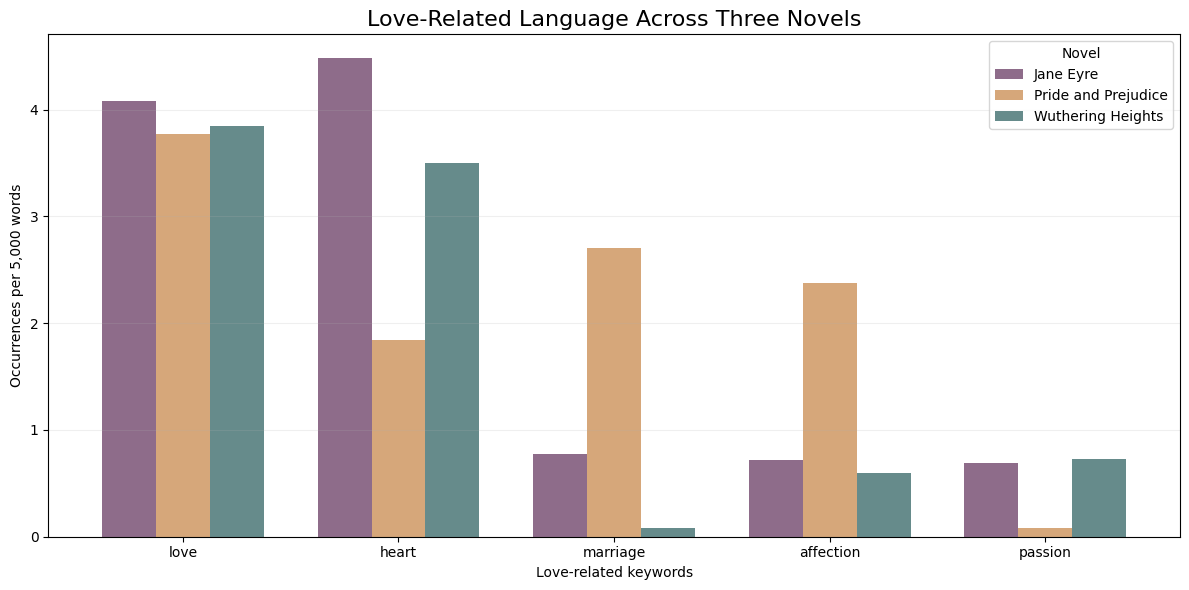

In [ ]:

import matplotlib.pyplot as plt

# Compare normalized keyword frequencies
ax = normalized.T.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#8E6C8A", "#D6A77A", "#668B8B"],
    width=0.75
)

plt.title("Love-Related Language Across Three Novels", fontsize=16)
plt.xlabel("Love-related keywords")
plt.ylabel("Occurrences per 5,000 words")
plt.xticks(rotation=0)
plt.legend(title="Novel")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.show()


## Preliminary findings

Love appears at a similar frequency across all three novels, while marriage is more common in Pride and Prejudice and heart is more common in Jane Eyre.

In [ ]:

# Examine how love-related words are used in context

for title in files:

    print("\n" + "=" * 70)
    print(title.upper())
    print("=" * 70)

    for word in keywords:

        # Find paragraphs containing the selected keyword
        examples = df[
            (df["Novel"] == title) &
            (df[word] > 0)
        ]

        print("\nKEYWORD:", word.upper())

        # Select up to two random examples
        sample = examples.sample(
            n=min(2, len(examples)),
            random_state=42
        )

        for _, row in sample.iterrows():
            print(f"\nChapter {row['Chapter']}, Paragraph {row['Paragraph']}")
            print(row["Text"])



PRIDE AND PREJUDICE

KEYWORD: LOVE

Chapter 25, Paragraph 10
“Oh, yes!--of that kind of love which I suppose him to have felt. Poor Jane! I am sorry for her, because, with her disposition, she may not get over it immediately. It had better have happened to _you_, Lizzy; you would have laughed yourself out of it sooner. But do you think she would be prevailed upon to go back with us? Change of scene might be of service--and perhaps a little relief from home may be as useful as anything.”

Chapter 1, Paragraph 18
“Design! Nonsense, how can you talk so! But it is very likely that he _may_ fall in love with one of them, and therefore you must visit him as soon as he comes.”

KEYWORD: HEART

Chapter 55, Paragraph 50
This naturally introduced a panegyric from Jane on his diffidence, and the little value he put on his own good qualities. Elizabeth was pleased to find that he had not betrayed the interference of his friend; for, though Jane had the most generous and forgiving heart in the wor

## Defining Romantic Love

For our analysis, we define romantic love as language that expresses romantic attraction, emotional intimacy, desire, attachment, or commitment between individuals.

We recognize that words such as love, heart, affection, marriage, and passion do not always describe romantic relationships. They can also represent family relationships, friendships, fear, anger, or other emotions. Similarly, romantic love can be expressed without using any of these specific words.

To address this limitation, we will manually examine passages from each novel and compare our interpretations with the results produced by our code.

In [ ]:

from textwrap import fill

# Identify paragraphs containing our original keywords
df["Keyword detected"] = df[keywords].sum(axis=1) > 0

# Select passages for manual evaluation
samples = []

for title in files:

    book = df[df["Novel"] == title]

    detected = book[book["Keyword detected"]]
    undetected = book[~book["Keyword detected"]]

    samples.append(detected.sample(3, random_state=42))
    samples.append(undetected.sample(3, random_state=42))

# Shuffle the passages to reduce bias
evaluation = pd.concat(samples).sample(
    frac=1, random_state=42
).reset_index(drop=True)

# Give each passage an identification number
evaluation["ID"] = range(1, len(evaluation) + 1)

# Display passages without revealing keyword detection
for _, row in evaluation.iterrows():

    print("\n" + "=" * 70)
    print("Passage", row["ID"])
    print(row["Novel"])
    print("Chapter:", row["Chapter"])
    print("Paragraph:", row["Paragraph"])
    print()
    print(fill(row["Text"], width=90))



Passage 1
Pride and Prejudice
Chapter: 25
Paragraph: 8

“But that expression of 'violently in love' is so hackneyed, so doubtful, so indefinite,
that it gives me very little idea. It is as often applied to feelings which arise from a
half-hour's acquaintance, as to a real, strong attachment. Pray, how _violent was_ Mr.
Bingley's love?”

Passage 2
Pride and Prejudice
Chapter: 42
Paragraph: 13

“My love, should not you like to see a place of which you have heard so much?” said her
aunt; “a place, too, with which so many of your acquaintances are connected. Wickham
passed all his youth there, you know.”

Passage 3
Jane Eyre
Chapter: 15
Paragraph: 2

He then said that she was the daughter of a French opera-dancer, Celine Varens, towards
whom he had once cherished what he called a "_grande passion_." This passion Celine had
professed to return with even superior ardour. He thought himself her idol, ugly as he
was: he believed, as he said, that she preferred his "_taille d'athlete_" to the 

In [ ]:

# Prepare passages for manual evaluation

review = evaluation[
    ["ID", "Novel", "Chapter", "Paragraph", "Text"]
].copy()

# Add columns for manual classification
review["Classification"] = ""
review["Reason"] = ""

# Save the evaluation table
review.to_csv("romantic_passage_review.csv", index=False)

# Download the table
from google.colab import files as colab_files
colab_files.download("romantic_passage_review.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Preliminary AI-assisted passage classifications
# To be reviewed by our group

classifications = {
    1: "Romantic",
    2: "Non-romantic",
    3: "Romantic",
    4: "Romantic",
    5: "Non-romantic",
    6: "Unclear",
    7: "Non-romantic",
    8: "Unclear",
    9: "Unclear",
    10: "Romantic",
    11: "Unclear",
    12: "Non-romantic",
    13: "Unclear",
    14: "Non-romantic",
    15: "Non-romantic",
    16: "Unclear",
    17: "Non-romantic",
    18: "Romantic"
}

# Add classifications to our evaluation dataset
evaluation["Classification"] = evaluation["ID"].map(classifications)

# Compare classifications with keyword detection
display(evaluation[
    ["ID", "Novel", "Keyword detected", "Classification"]
])

# Summarize classifications
display(evaluation["Classification"].value_counts())


,ID,Novel,Keyword detected,Classification
0,1,Pride and Prejudice,True,Romantic
1,2,Pride and Prejudice,True,Non-romantic
2,3,Jane Eyre,True,Romantic
3,4,Pride and Prejudice,False,Romantic
4,5,Pride and Prejudice,False,Non-romantic
5,6,Wuthering Heights,True,Unclear
6,7,Wuthering Heights,False,Non-romantic
7,8,Wuthering Heights,False,Unclear
8,9,Jane Eyre,False,Unclear
9,10,Pride and Prejudice,True,Romantic


,count
Classification,
Non-romantic,7
Unclear,6
Romantic,5


In [ ]:

# Investigate passages that need additional context

unclear = evaluation[evaluation["Classification"] == "Unclear"]

for _, row in unclear.iterrows():

    print("\n" + "=" * 70)
    print("PASSAGE", row["ID"])
    print(row["Novel"], "- Chapter", row["Chapter"])

    # Retrieve surrounding paragraphs
    context = df[
        (df["Novel"] == row["Novel"]) &
        (df["Chapter"] == row["Chapter"]) &
        (df["Paragraph"].between(
            row["Paragraph"] - 2,
            row["Paragraph"] + 2
        ))
    ]

    for _, passage in context.iterrows():

        if passage["Paragraph"] == row["Paragraph"]:
            print("\n>>> ORIGINAL PASSAGE <<<")
        else:
            print("\nSurrounding paragraph:")

        print(fill(passage["Text"], width=90))



PASSAGE 6
Wuthering Heights - Chapter 9

Surrounding paragraph:
'Who can help it? Of course I do,' she answered.

Surrounding paragraph:
Then I put her through the following catechism: for a girl of twenty-two it was not
injudicious.

>>> ORIGINAL PASSAGE <<<
'Why do you love him, Miss Cathy?'

Surrounding paragraph:
'Nonsense, I do--that's sufficient.'

Surrounding paragraph:
'By no means; you must say why?'

PASSAGE 8
Wuthering Heights - Chapter 10

Surrounding paragraph:
'A little more than you have thought of me,' he murmured. 'I heard of your marriage,
Cathy, not long since; and, while waiting in the yard below, I meditated this plan--just
to have one glimpse of your face, a stare of surprise, perhaps, and pretended pleasure;
afterwards settle my score with Hindley; and then prevent the law by doing execution on
myself. Your welcome has put these ideas out of my mind; but beware of meeting me with
another aspect next time! Nay, you'll not drive me off again. You were really sorry

In [ ]:

# Collect surrounding context for unclear passages

context_review = []

for _, row in unclear.iterrows():

    context = df[
        (df["Novel"] == row["Novel"]) &
        (df["Chapter"] == row["Chapter"]) &
        (df["Paragraph"].between(
            row["Paragraph"] - 2,
            row["Paragraph"] + 2
        ))
    ]

    context_review.append({
        "ID": row["ID"],
        "Novel": row["Novel"],
        "Chapter": row["Chapter"],
        "Original passage": row["Text"],
        "Surrounding context": "\n\n".join(context["Text"])
    })

context_df = pd.DataFrame(context_review)

context_df.to_csv("context_review.csv", index=False)

colab_files.download("context_review.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Refine classifications after reading surrounding paragraphs

updated_classifications = {
    6: "Unclear",
    8: "Romantic",
    9: "Non-romantic",
    11: "Non-romantic",
    13: "Romantic",
    16: "Unclear"
}

# Update the original classifications
classifications.update(updated_classifications)

evaluation["Classification"] = evaluation["ID"].map(classifications)

# Display the revised results
display(evaluation[
    ["ID", "Novel", "Keyword detected", "Classification"]
])

print("Updated classification totals:")
display(evaluation["Classification"].value_counts())


,ID,Novel,Keyword detected,Classification
0,1,Pride and Prejudice,True,Romantic
1,2,Pride and Prejudice,True,Non-romantic
2,3,Jane Eyre,True,Romantic
3,4,Pride and Prejudice,False,Romantic
4,5,Pride and Prejudice,False,Non-romantic
5,6,Wuthering Heights,True,Unclear
6,7,Wuthering Heights,False,Non-romantic
7,8,Wuthering Heights,False,Romantic
8,9,Jane Eyre,False,Non-romantic
9,10,Pride and Prejudice,True,Romantic


Updated classification totals:


,count
Classification,
Non-romantic,9
Romantic,7
Unclear,2
